# 04. Descritiva

Fase 4. Descrição da base `data/03_processed/boletins.csv`, sem nenhuma
estimativa de elasticidade.

Quatro saídas:

- a) variação de preço de Inteira dentro de cada partida;
- b) composição do público por regime e temporada;
- c) nível de preço de Inteira por clube mandante e temporada;
- d) relação bruta entre preço e público por setor e jogo.

Todo resultado traz o número de observações. Os gráficos são salvos em
`figuras/04_descritiva/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RAIZ / "figuras" / "04_descritiva"
FIG.mkdir(parents=True, exist_ok=True)

base = pd.read_csv(RAIZ / "data" / "03_processed" / "boletins.csv")
clubes = pd.read_csv(RAIZ / "referencias" / "clubes.csv")

# Padronização de nome de clube por dicionário explícito. Nome sem
# correspondência é listado, não descartado.
mapa = dict(zip(clubes.nome_boletim, clubes.clube))
sem_mapa = sorted(set(base.mandante) - set(mapa))
print("Mandantes sem correspondência no dicionário:", sem_mapa or "nenhum")
base["clube_mandante"] = base.mandante.map(mapa)

REGIMES = ["mercado", "socio", "contrato", "promocional", "gratuidade", "nao_vendido"]
print(f"Linhas: {len(base):,}  Jogos: {base.groupby(['ano', 'jogo']).ngroups}")

Mandantes sem correspondência no dicionário: nenhum
Linhas: 12,241  Jogos: 388


## Subconjunto identificador

Linhas de regime mercado, categoria Inteira, com vendidos maior que zero.

In [2]:
ident = base[(base.regime == "mercado") & (base.categoria == "Inteira") & (base.vendidos > 0)].copy()
precos_por_jogo = ident.groupby(["ano", "jogo"]).preco.nunique()
jogos_com_variacao = precos_por_jogo[precos_por_jogo >= 2].index
ident["jogo_com_variacao"] = ident.set_index(["ano", "jogo"]).index.isin(jogos_com_variacao)

print(f"Observações: {len(ident):,}")
print(f"Jogos com Inteira de mercado: {ident.groupby(['ano', 'jogo']).ngroups}")
print(f"Jogos com ao menos dois preços distintos: {len(jogos_com_variacao)}")
print(f"Observações nesses jogos: {ident.jogo_com_variacao.sum():,}")
print(f"Das quais com subtipo P.C.D. (preco_regulado verdadeiro): {(ident.subtipo == 'P.C.D.').sum()}")

Observações: 2,335
Jogos com Inteira de mercado: 387
Jogos com ao menos dois preços distintos: 314
Observações nesses jogos: 2,152
Das quais com subtipo P.C.D. (preco_regulado verdadeiro): 45


## a) Variação de preço intra-partida

Para cada jogo com ao menos dois preços distintos de Inteira de mercado, a
razão entre o maior e o menor preço.

       com P.C.D.  sem P.C.D.
count     314.000     314.000
mean        2.899       2.853
std         2.445       2.448
min         1.136       1.136
25%         1.667       1.667
50%         2.000       2.000
75%         2.833       2.625
90%         5.400       5.400
max        20.000      20.000


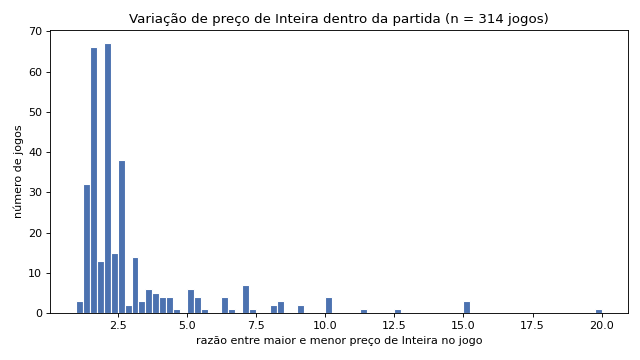

In [3]:
faixa = ident.groupby(["ano", "jogo"]).preco.agg(["min", "max", "nunique"])
faixa = faixa[faixa["nunique"] >= 2]
faixa["razao"] = faixa["max"] / faixa["min"]

sem_pcd = ident[ident.subtipo != "P.C.D."].groupby(["ano", "jogo"]).preco.agg(["min", "max", "nunique"])
sem_pcd = sem_pcd[sem_pcd["nunique"] >= 2]
sem_pcd["razao"] = sem_pcd["max"] / sem_pcd["min"]

resumo_a = pd.DataFrame({
    "com P.C.D.": faixa.razao.describe(percentiles=[0.25, 0.5, 0.75, 0.9]),
    "sem P.C.D.": sem_pcd.razao.describe(percentiles=[0.25, 0.5, 0.75, 0.9]),
}).round(3)
print(resumo_a)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(faixa.razao, bins=np.arange(1, faixa.razao.max() + 0.25, 0.25), color="#4C72B0", edgecolor="white")
ax.set_xlabel("razão entre maior e menor preço de Inteira no jogo")
ax.set_ylabel("número de jogos")
ax.set_title(f"Variação de preço de Inteira dentro da partida (n = {len(faixa)} jogos)")
fig.tight_layout()
fig.savefig(FIG / "a_variacao_intrapartida.png", dpi=150)
plt.show()

## b) Composição do público por regime e temporada

Ingressos por regime e temporada
      mercado   socio  contrato  promocional  gratuidade  nao_vendido  revisão    total  jogos
ano                                                                                           
2023   672523  558677    116161            0       28195         5512      754  1381822    109
2024   628522  539554    132079            0       22322        21180     3627  1347284    104
2025   404609  630853    210546            0       20683        41063        0  1307754    103
2026   388946  285197     71016         3064       22880        13266        0   784369     72

Percentual por temporada
regime  mercado  socio  contrato  promocional  gratuidade  nao_vendido  revisão
ano                                                                            
2023       48.7   40.4       8.4          0.0         2.0          0.4      0.1
2024       46.7   40.0       9.8          0.0         1.7          1.6      0.3
2025       30.9   48.2      16.1          0.0      

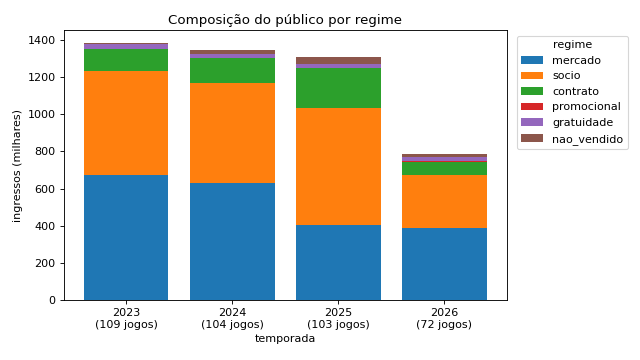

In [4]:
comp = (base[base.regime.isin(REGIMES)]
        .pivot_table(index="ano", columns="regime", values="vendidos", aggfunc="sum", fill_value=0)
        .reindex(columns=REGIMES, fill_value=0))
comp["revisão"] = base[base.regime.isna()].groupby("ano").vendidos.sum().reindex(comp.index, fill_value=0)
comp["total"] = comp.sum(axis=1)
jogos_ano = base.groupby("ano").jogo.nunique().rename("jogos")
tabela_b = comp.join(jogos_ano)
pct_b = (comp[REGIMES + ["revisão"]].div(comp["total"], axis=0) * 100).round(1)
print("Ingressos por regime e temporada")
print(tabela_b.to_string())
print()
print("Percentual por temporada")
print(pct_b.to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
fundo = np.zeros(len(comp))
for regime in REGIMES:
    ax.bar(comp.index.astype(str), comp[regime] / 1000, bottom=fundo, label=regime)
    fundo += comp[regime].values / 1000
ax.set_xlabel("temporada")
ax.set_ylabel("ingressos (milhares)")
rotulos = [f"{a}\n({j} jogos)" for a, j in jogos_ano.items()]
ax.set_xticks(range(len(comp)))
ax.set_xticklabels(rotulos)
ax.set_title("Composição do público por regime")
ax.legend(title="regime", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "b_composicao_regime.png", dpi=150)
plt.show()

## c) Nível de preço de Inteira por clube mandante e temporada

Observação: cada linha do subconjunto identificador (setor e subtipo de um
jogo), sem ponderação por ingressos. Só clubes com ao menos 8 jogos como
mandante na base.

Clubes fora (menos de 8 jogos como mandante): {'Capivariano': 4, 'Ferroviária': 6, 'Primavera': 4, 'São Bento': 6}
                           jogos  observacoes     q1  mediana     q3
clube_mandante       ano                                            
Botafogo             2023      6           28  100.0   120.00  197.5
                     2024      6           29  100.0   120.00  200.0
                     2025      6           22  120.0   150.00  150.0
                     2026      4           18   80.0   125.00  300.0
Corinthians          2023      7           66   65.0   130.00  220.0
                     2024      6           46   90.0   150.00  230.0
                     2025      9           76  120.0   180.00  260.0
                     2026      4           33  110.0   180.00  260.0
Grêmio Novorizontino 2024      6           24   40.0    40.00   50.0
                     2025      6           22   25.0    40.00   80.0
                     2026      7           29   40.0   10

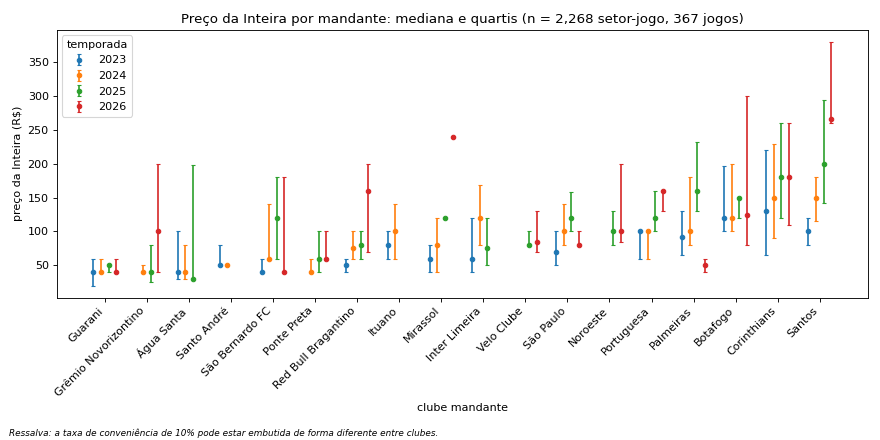

In [5]:
jogos_mandante = base.drop_duplicates(["ano", "jogo"]).groupby("clube_mandante").size()
elegiveis = jogos_mandante[jogos_mandante >= 8].index
fora = jogos_mandante[jogos_mandante < 8]
print("Clubes fora (menos de 8 jogos como mandante):", fora.to_dict())

c = ident[ident.clube_mandante.isin(elegiveis)]
tabela_c = (c.groupby(["clube_mandante", "ano"])
            .agg(jogos=("jogo", "nunique"), observacoes=("preco", "size"),
                 q1=("preco", lambda s: s.quantile(0.25)), mediana=("preco", "median"),
                 q3=("preco", lambda s: s.quantile(0.75)))
            .round(2))
print(tabela_c.to_string())

ordem = c.groupby("clube_mandante").preco.median().sort_values().index
anos = sorted(c.ano.unique())
deslocamento = dict(zip(anos, np.linspace(-0.27, 0.27, len(anos))))
fig, ax = plt.subplots(figsize=(11, 5.5))
for ano in anos:
    t = tabela_c.xs(ano, level="ano").reindex(ordem).dropna()
    x = np.array([list(ordem).index(cl) for cl in t.index]) + deslocamento[ano]
    ax.errorbar(x, t.mediana, yerr=[t.mediana - t.q1, t.q3 - t.mediana], fmt="o", ms=4,
                capsize=2, label=str(ano))
ax.set_xticks(range(len(ordem)))
ax.set_xticklabels(ordem, rotation=45, ha="right")
ax.set_ylabel("preço da Inteira (R$)")
ax.set_xlabel("clube mandante")
ax.set_title(f"Preço da Inteira por mandante: mediana e quartis (n = {len(c):,} setor-jogo, {c.groupby(['ano', 'jogo']).ngroups} jogos)")
ax.legend(title="temporada")
fig.text(0.01, 0.01, "Ressalva: a taxa de conveniência de 10% pode estar embutida de forma diferente entre clubes.",
         fontsize=8, style="italic")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "c_preco_por_mandante.png", dpi=150)
plt.show()

**Ressalva.** A taxa de conveniência de 10% pode estar embutida de forma
diferente entre clubes. Em parte dos boletins ela aparece como categoria
própria (Meia Social, Solidário), em outros pode estar dentro do preço da
Inteira. A comparação de nível entre clubes herda essa diferença.

## d) Relação bruta entre preço e público por setor e jogo

Observação: setor de um jogo com uma única Inteira de mercado no
subconjunto identificador. Eixo y: soma dos ingressos de regime mercado
vendidos no setor.

**Esta nuvem não é elasticidade.** A inclinação dela está contaminada por
endogeneidade: clube caro é clube grande. Preço e público sobem juntos
porque os dois dependem da demanda pelo clube e pelo jogo, não porque o
preço cause o público.

Setores-jogo com Inteira de mercado: 2,236
Com uma única Inteira (entram na nuvem): 2,197
Jogos: 387
       preco_inteira  ingressos_mercado
count         2197.0             2197.0
mean           121.7              893.1
std             89.2             1383.4
min             20.0                1.0
25%             60.0               99.0
50%            100.0              343.0
75%            150.0             1038.0
max            900.0             9679.0


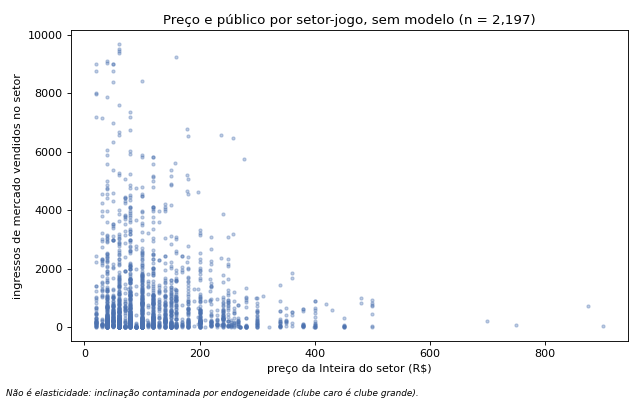

In [6]:
inteira_setor = ident.groupby(["ano", "jogo", "setor"]).preco.agg(["nunique", "first"])
unica = inteira_setor[inteira_setor["nunique"] == 1]["first"].rename("preco_inteira")
publico_setor = (base[base.regime == "mercado"].groupby(["ano", "jogo", "setor"]).vendidos.sum()
                 .rename("ingressos_mercado"))
d = pd.concat([unica, publico_setor], axis=1, join="inner")
print(f"Setores-jogo com Inteira de mercado: {len(inteira_setor):,}")
print(f"Com uma única Inteira (entram na nuvem): {len(d):,}")
print(f"Jogos: {d.reset_index().groupby(['ano', 'jogo']).ngroups}")
print(d.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(d.preco_inteira, d.ingressos_mercado, s=8, alpha=0.35, color="#4C72B0")
ax.set_xlabel("preço da Inteira do setor (R$)")
ax.set_ylabel("ingressos de mercado vendidos no setor")
ax.set_title(f"Preço e público por setor-jogo, sem modelo (n = {len(d):,})")
fig.text(0.01, 0.01, "Não é elasticidade: inclinação contaminada por endogeneidade (clube caro é clube grande).",
         fontsize=8, style="italic")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "d_preco_publico_setor.png", dpi=150)
plt.show()